<a href="https://colab.research.google.com/github/nastyaatt/IAD_tykhonova/blob/main/tykhonova_lab1_iad.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Лабораторна робота №1
ФБ-62мп Тихонова Анастасія

In [9]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier

from sklearn.metrics import classification_report, confusion_matrix

In [10]:
df = pd.read_csv("cybersecurity_network_logs.csv")
df.head()

,Protocol,Packet_Size_Bytes,Connection_Duration_ms,Failed_Logins,Geo_Distance_km,Is_Malicious
0,TCP,805,59,0,1169,0
1,TCP,926,58,0,379,0
2,TCP,974,3,0,79,0
3,ICMP,6121,16,0,1044,1
4,TCP,119,64,1,788,0


**Ознайомлення з датасетом**

In [11]:
print("Розмір датасета:", df.shape)

Розмір датасета: (25000, 6)


In [12]:
print("Назви колонок:")
print(df.columns.tolist())

Назви колонок:
['Protocol', 'Packet_Size_Bytes', 'Connection_Duration_ms', 'Failed_Logins', 'Geo_Distance_km', 'Is_Malicious']




*   **'Protocol'** - мережевий протокол
*   **'Packet_Size_Bytes'** - розмір переданного пакета

*   **'Connection_Duration_ms'** - тривалість мережевого з'єднання
*   **'Failed_Logins'** - кількість невдалих спроб входу


*   **'Geo_Distance_km'** - географічна відстань до джерела IP-адреси
*   **'Is_Malicious'** - визначає клас мережевого з'єднання: 0 - нормальний трафік, 1 - шкідливий трафік










In [13]:
print(df.dtypes)

Protocol                  object
Packet_Size_Bytes          int64
Connection_Duration_ms     int64
Failed_Logins              int64
Geo_Distance_km            int64
Is_Malicious               int64
dtype: object


In [14]:
# цільова змінна, яку потрібно передбачити
target = "Is_Malicious"

# усі колонки, окрім цільової
features = df.drop(target, axis=1)

# колонка, яку прогнозуємо
y = df[target]

print("Features:")
print(features.columns.tolist())

print("\nTarget:")
print(target)

Features:
['Protocol', 'Packet_Size_Bytes', 'Connection_Duration_ms', 'Failed_Logins', 'Geo_Distance_km']

Target:
Is_Malicious


**Розподіл класів**

In [15]:
# підрахунок кількості об'єктів кожного класу
print(df["Is_Malicious"].value_counts())

# розрахунок відсоткового розподілу класів
print("\nВідсотковий розподіл:")
print((df["Is_Malicious"].value_counts(normalize=True) * 100).round(2))

Is_Malicious
0    23753
1     1247
Name: count, dtype: int64

Відсотковий розподіл:
Is_Malicious
0    95.01
1     4.99
Name: proportion, dtype: float64


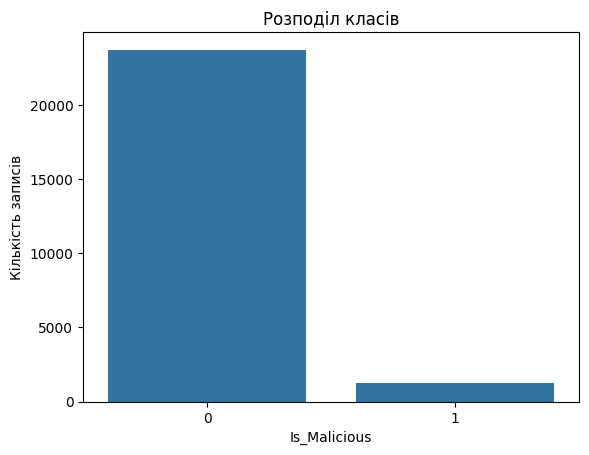

In [16]:
# візуалізація кількості об'єктів кожного класу
sns.countplot(x=df["Is_Malicious"])

plt.title("Розподіл класів")
plt.xlabel("Is_Malicious")
plt.ylabel("Кількість записів")
plt.show()

Можна побачити, що датасет є незбалансованим. Нормальний трафік тут становить близько 95%, а шкідливий лише близько 5%. Власне через це accuracy не буде надійною метрикою, оскільки навіть якщо модель на все буде казати, що це Нормальний трафік, точність у нашому випадку буде 95%. А це очевидно не найкращий спосіб визначення. Томі основну увагу тут буде приділено саме precision, recall та F1-score, а при розбитті буде використовуватись stratify, яка буде рівномірно розподіляти значення для навчальної і тестової вибірок

**Перевірка пропущених значень**

In [17]:
# перевірка кількості пропущених значень у кожній колонці
print(df.isnull().sum())

Protocol                  0
Packet_Size_Bytes         0
Connection_Duration_ms    0
Failed_Logins             0
Geo_Distance_km           0
Is_Malicious              0
dtype: int64


У даному датасеті відсутні пропущені значення. Тому додаткове заповнення або видалення пропущених значень не потрібне

**Попередня обробка даних**

In [18]:
# перетворення категоріальної колонки Protocol на окремі бінарні колонки
df_encoded = pd.get_dummies(df, columns=["Protocol"], dtype=int)

# переглядаємо результат
df_encoded.head()

,Packet_Size_Bytes,Connection_Duration_ms,Failed_Logins,Geo_Distance_km,Is_Malicious,Protocol_ICMP,Protocol_TCP,Protocol_UDP
0,805,59,0,1169,0,0,1,0
1,926,58,0,379,0,0,1,0
2,974,3,0,79,0,0,1,0
3,6121,16,0,1044,1,1,0,0
4,119,64,1,788,0,0,1,0


Оскільки ознака 'Protocol' є категоріальною, її було закодовано методом one-hot encoding

---


Для кожного протоколу створюється окрема
бінарна ознака. Інші ознаки вже і так мають числовий формат, тому додаткового кодування не потребують

**Дослідження даних**

***Хітмап кореляцій***

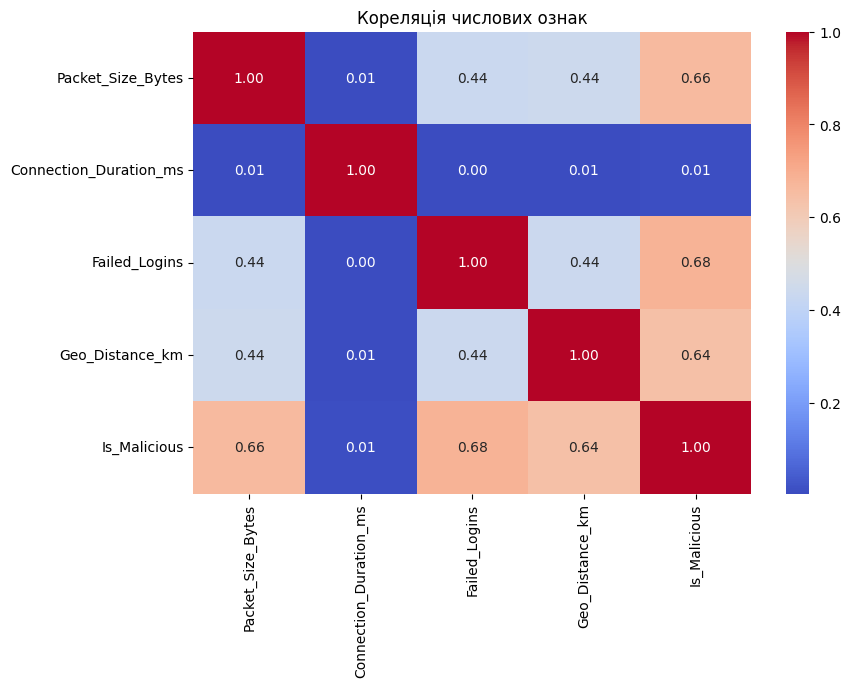

In [19]:
# вибір числові ознаки для аналізу кореляцій
numeric_columns = ["Packet_Size_Bytes", "Connection_Duration_ms", "Failed_Logins", "Geo_Distance_km", "Is_Malicious"]

# обчислення кореляції між ознаками
correlation = df[numeric_columns].corr()

# побудова хітмап
plt.figure(figsize=(9, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Кореляція числових ознак")
plt.show()

На хітмап можна побачити, наскільки числові ознаки пов'язані між собою та з цільовою змінною


---

Найбільш помітний зв'язок із 'Is_Malicious' мають розмір пакета, кількість невдалих входів та географічна відстань. Це свідчить про те, що ці характеристики можуть бути корисними для класифікації мережевого трафіку

**Гістограми**

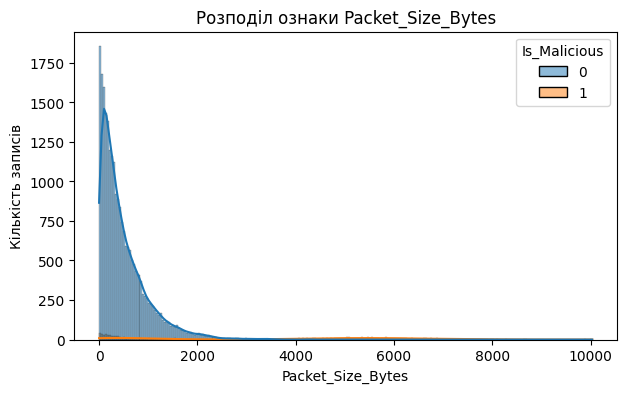

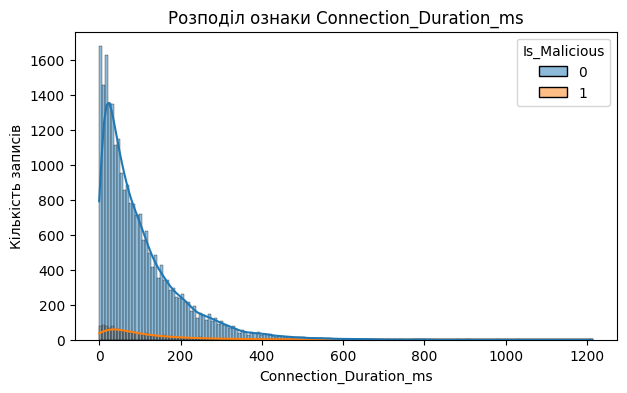

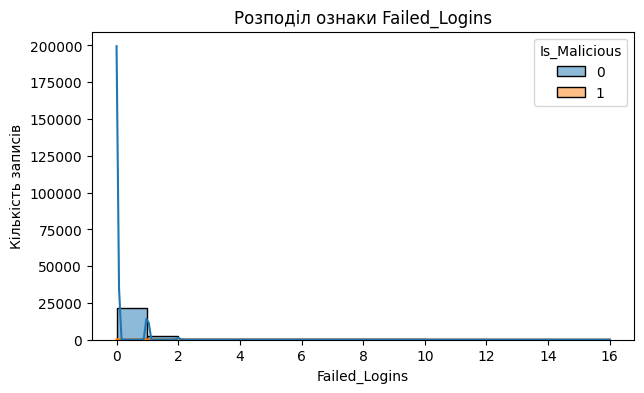

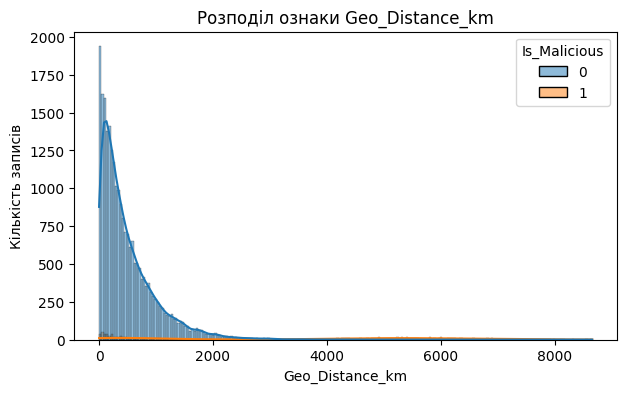

In [20]:
columns = ["Packet_Size_Bytes", "Connection_Duration_ms", "Failed_Logins", "Geo_Distance_km"]

for column in columns:
  plt.figure(figsize=(7, 4))
  sns.histplot(data=df, x=column, hue="Is_Malicious", kde=True)

  plt.title(f"Розподіл ознаки {column}")
  plt.xlabel(column)
  plt.ylabel("Кількість записів")
  plt.show()

Гістограми показують розподіл значень основних числових ознак для різних класів трафіку


---

Можна помітити, що розподіли нормального та шкідливого трафіку відрізняються, особливо для розміру пакетів, кількості невдалих входів та географічної відстані. це означає, що дані ознаки можуть допомагати моделям розрізняти два класи

**Boxplot**

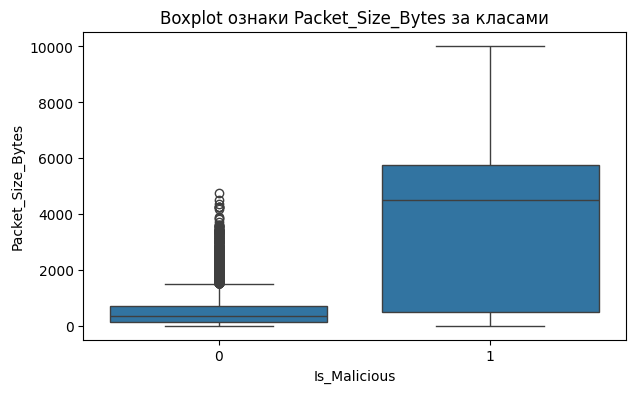

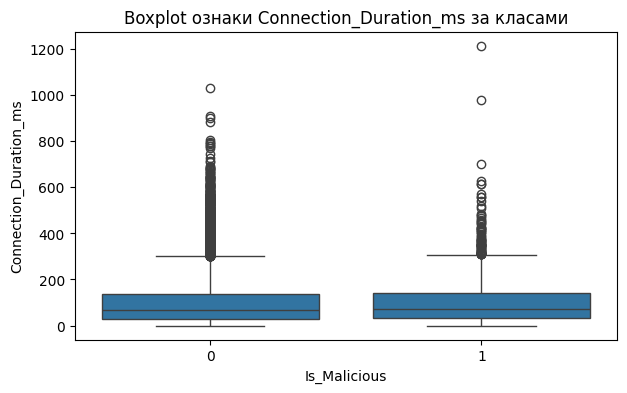

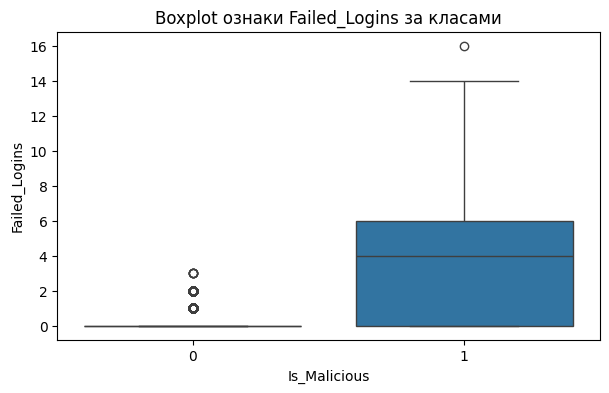

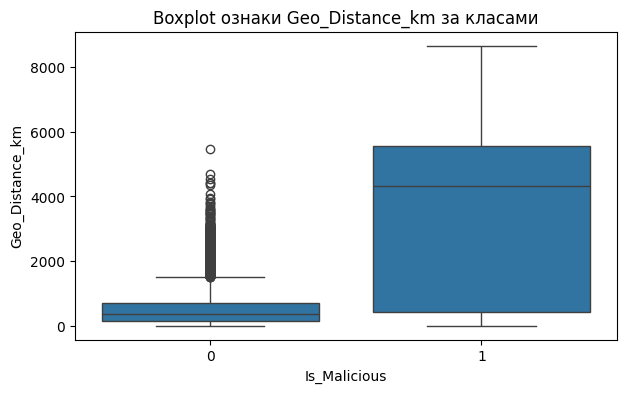

In [21]:
# побудова боксплот для основних числових ознак відносно цільової змінної
for column in columns:
  plt.figure(figsize=(7, 4))

  sns.boxplot(data=df, x="Is_Malicious", y=column)

  plt.title(f"Boxplot ознаки {column} за класами")
  plt.xlabel("Is_Malicious")
  plt.ylabel(column)
  plt.show()

Boxplot дозволяють порівняти розподіл числових ознак для нормального та шкідливого трафіку


---

Для деяких ознак медіани та діапазони значень між класами помітно відрізняються. Також на графіку присотні викиди, що є характерним для мережевих даних. Вони можуть містити корисну інформацію про аномальну або шкідливу активність

**Підготовка даних до навчання**

In [22]:
# відокремлення features від target
X = df_encoded.drop("Is_Malicious", axis=1)
y = df_encoded["Is_Malicious"]

# розділення даних на навчальну та тестову вибірки (80% навчальна, 20% тестова)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Розмір training:", X_train.shape)
print("Розмір test:", X_test.shape)

Розмір training: (20000, 7)
Розмір test: (5000, 7)


**Масштабування**

In [23]:
# створюється об'єкт для стандартизації даних
scaler = StandardScaler()

# скалер навчається тільки на навчальних даних
X_train_scaled = scaler.fit_transform(X_train)

# до тестових застосовується вже отримане масштабування
X_test_scaled = scaler.transform(X_test)

In [24]:
print("Середні:", scaler.mean_)
print("Розкиди:", scaler.scale_)

Середні: [6.4869805e+02 9.9858200e+01 2.7480000e-01 6.4446760e+02 9.7650000e-02
 7.0055000e-01 2.0180000e-01]
Розкиди: [1.01503254e+03 9.87784318e+01 1.11057866e+00 9.88741711e+02
 2.96840829e-01 4.58017137e-01 4.01343693e-01]


Для kNN та SVM виконується стандартизація за допомогою StandardScaler


---

Scaler навчається тільки на навчальній вибірці, а до тестової вибірки застосовується те саме перетворення. Це дозволяє уникнути використання інформації з тестових даних під час навчання

**Навчання моделей**

***kNN***

In [25]:
# сворення моделі kNN
knn = KNeighborsClassifier(n_neighbors=5)

# навчання моделі на масштабованих даних
knn.fit(X_train_scaled, y_train)

# робимо передбачення
knn_pred = knn.predict(X_test_scaled)

print("kNN")
print(classification_report(y_test, knn_pred))
print("Confusion matrix:")
print(confusion_matrix(y_test, knn_pred))

kNN
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      4751
           1       0.99      0.88      0.93       249

    accuracy                           0.99      5000
   macro avg       0.99      0.94      0.96      5000
weighted avg       0.99      0.99      0.99      5000

Confusion matrix:
[[4748    3]
 [  30  219]]


***Decision Tree***

In [26]:
# створення дерева рішень
tree = DecisionTreeClassifier(random_state=42)

# навчання моделі
tree.fit(X_train, y_train)

# робиться передбачення
tree_pred = tree.predict(X_test)

print("Decision Tree")
print(classification_report(y_test, tree_pred))
print("Confusion matrix:")
print(confusion_matrix(y_test, tree_pred))

Decision Tree
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      4751
           1       0.86      0.90      0.88       249

    accuracy                           0.99      5000
   macro avg       0.93      0.95      0.94      5000
weighted avg       0.99      0.99      0.99      5000

Confusion matrix:
[[4716   35]
 [  25  224]]


***SVM***

In [27]:
# створення SVM
svm = SVC()

# навчання можелі на масштабованих даних
svm.fit(X_train_scaled, y_train)

# робимо передбачення
svm_pred = svm.predict(X_test_scaled)

print("SVM")
print(classification_report(y_test, svm_pred))
print("Confusion matrix:")
print(confusion_matrix(y_test, svm_pred))

SVM
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      4751
           1       0.99      0.88      0.93       249

    accuracy                           0.99      5000
   macro avg       0.99      0.94      0.96      5000
weighted avg       0.99      0.99      0.99      5000

Confusion matrix:
[[4749    2]
 [  30  219]]


***Random Forest***

In [28]:
# створюємо Random forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)

# навчання моделі
rf.fit(X_train, y_train)

# робимо передбачення
rf_pred = rf.predict(X_test)

print("Random Forest")
print(classification_report(y_test, rf_pred))
print("Confusion matrix:")
print(confusion_matrix(y_test, rf_pred))

Random Forest
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4751
           1       0.98      0.91      0.94       249

    accuracy                           0.99      5000
   macro avg       0.99      0.95      0.97      5000
weighted avg       0.99      0.99      0.99      5000

Confusion matrix:
[[4747    4]
 [  23  226]]


***AdaBoost***

In [29]:
# створення AdaBoost
ada = AdaBoostClassifier(n_estimators=100, random_state=42)

# навчання моделі
ada.fit(X_train, y_train)

# робимо передбачення
ada_pred = ada.predict(X_test)

print("AdaBoost")
print(classification_report(y_test, ada_pred))
print("Confusion matrix:")
print(confusion_matrix(y_test, ada_pred))

AdaBoost
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4751
           1       0.98      0.91      0.94       249

    accuracy                           0.99      5000
   macro avg       0.99      0.95      0.97      5000
weighted avg       0.99      0.99      0.99      5000

Confusion matrix:
[[4747    4]
 [  23  226]]


**Перевірка параметра k для kNN**






In [30]:
# перевірка різних значень кількості сусідів
knn_params = {"n_neighbors": [3, 5, 7, 9, 11]}

# тут перевіряються всі задані значення та буде обрано найкраще за F1-score
knn_grid = GridSearchCV(KNeighborsClassifier(), knn_params, cv=5, scoring="f1")

knn_grid.fit(X_train_scaled, y_train)

print("Найкраще значення n_neighbors:")
print(knn_grid.best_params_)

print("Найкращий F1-score на cross-validation:")
print(round(knn_grid.best_score_, 4))

Найкраще значення n_neighbors:
{'n_neighbors': 5}
Найкращий F1-score на cross-validation:
0.9423


**Підбір С та gamma для SVM**

In [31]:
# задаються значення параметрів SVM які потрібно перевірити
svm_params = {"C": [0.1, 1, 10, 100], "gamma": ["scale", 0.01, 0.1, 1]}

# перебираються комбінації С та gamma
svm_grid = GridSearchCV(SVC(), svm_params, cv=5, scoring="f1")

# навчаємо GridSearchCV
svm_grid.fit(X_train_scaled, y_train)

print("Найкращі параметри SVM:")
print(svm_grid.best_params_)

print("Найкращий F1-score на cross-validation:")
print(round(svm_grid.best_score_, 4))

Найкращі параметри SVM:
{'C': 10, 'gamma': 'scale'}
Найкращий F1-score на cross-validation:
0.9431


Тут гіперпараметри підбирались за допомогою GridSearchCV з 5ти кратною крос-валідацією на тренувальній вибірці за метрикою F1 для класу шкідливого трафіку. для kNN перевірядись непарні значення кількості сусідів навколо стандартного (від 3 до 11). Для SVM значення C та gamma перебирались за допомогою степені десятки. Підбір майже не змінив результат, оскільки дані добре розділяються і навіть стандартні налаштування дають близький до максимального результат

**Отримання остаточних передбачень**

In [32]:
# kNN з оптимальним параметром
knn_final = knn_grid.best_estimator_

# SVM з оптимальним параметром
svm_final = svm_grid.best_estimator_

# передбачення оптимізовних моделей
knn_final_pred = knn_final.predict(X_test_scaled)
svm_final_pred = svm_final.predict(X_test_scaled)

**Classification report для всіх моделей**

In [33]:
print("-kNN-")
print(classification_report(y_test, knn_final_pred))

print("-Decision Tree-")
print(classification_report(y_test, tree_pred))

print("-SVM-")
print(classification_report(y_test, svm_final_pred))

print("-Random Forest-")
print(classification_report(y_test, rf_pred))

print("-AdaBoost-")
print(classification_report(y_test, ada_pred))

-kNN-
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      4751
           1       0.99      0.88      0.93       249

    accuracy                           0.99      5000
   macro avg       0.99      0.94      0.96      5000
weighted avg       0.99      0.99      0.99      5000

-Decision Tree-
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      4751
           1       0.86      0.90      0.88       249

    accuracy                           0.99      5000
   macro avg       0.93      0.95      0.94      5000
weighted avg       0.99      0.99      0.99      5000

-SVM-
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      4751
           1       0.99      0.89      0.93       249

    accuracy                           0.99      5000
   macro avg       0.99      0.94      0.97      5000
weighted avg       0.99      0.99      0.99   

**Confusion matrix**

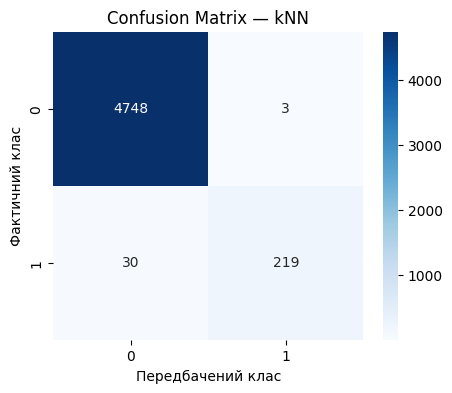

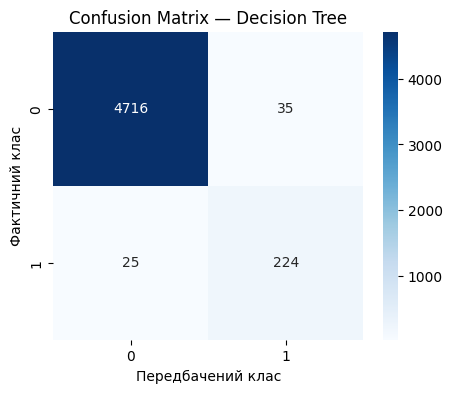

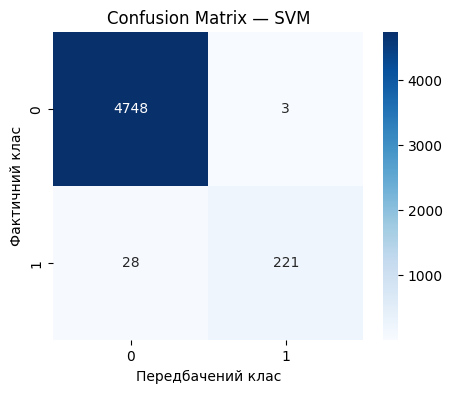

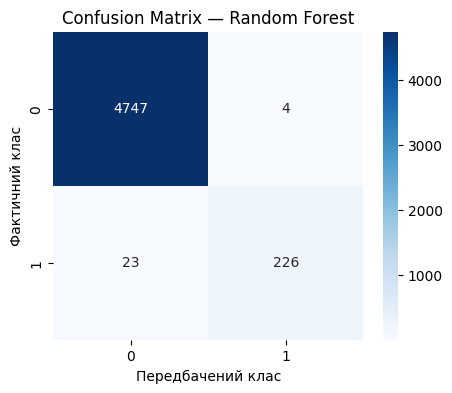

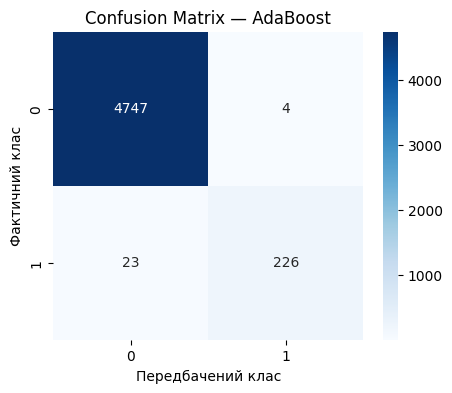

In [34]:
# збереження передбачення всіх моделей
predictions = {"kNN": knn_final_pred, "Decision Tree": tree_pred,"SVM": svm_final_pred, "Random Forest": rf_pred, "AdaBoost": ada_pred}

# побудова confusion matrix для кожної моделі
for name, pred in predictions.items():

    cm = confusion_matrix(y_test, pred)

    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

    plt.title(f"Confusion Matrix — {name}")
    plt.xlabel("Передбачений клас")
    plt.ylabel("Фактичний клас")
    plt.show()

**Порівняння моделей**

In [35]:
# створення таблиці для порівняння моделей
results = []

for name, pred in predictions.items():
    report = classification_report(y_test, pred, output_dict=True)

    results.append({
        "Model": name,
        "Accuracy": report["accuracy"],
        "Precision": report["1"]["precision"],
        "Recall": report["1"]["recall"],
        "F1-score": report["1"]["f1-score"]})

results_df = pd.DataFrame(results)

# вивід результати
results_df.round(4)

,Model,Accuracy,Precision,Recall,F1-score
0,kNN,0.9934,0.9865,0.8795,0.9299
1,Decision Tree,0.9880,0.8649,0.8996,0.8819
2,SVM,0.9938,0.9866,0.8876,0.9345
3,Random Forest,0.9946,0.9826,0.9076,0.9436
4,AdaBoost,0.9946,0.9826,0.9076,0.9436


**Графік порівняння моделей**

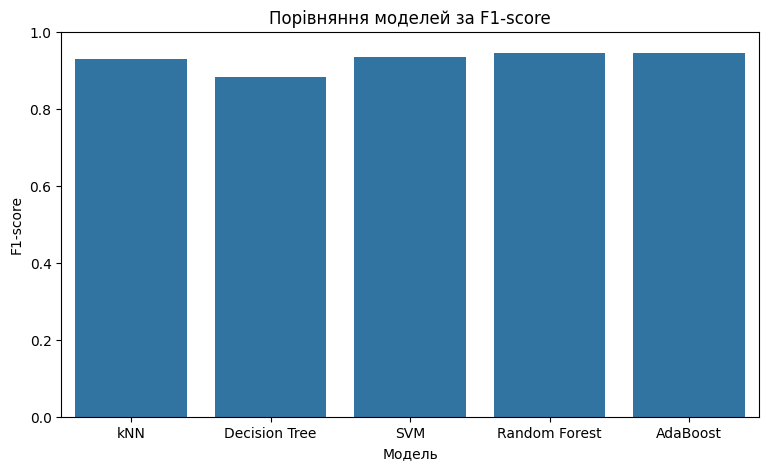

In [36]:
# порівняння F1-score моделей
plt.figure(figsize=(9, 5))

sns.barplot(data=results_df, x="Model", y="F1-score")

plt.title("Порівняння моделей за F1-score")
plt.xlabel("Модель")
plt.ylabel("F1-score")
plt.ylim(0, 1)

plt.show()

Висновок:
У роботі було порівняно 5 моделей для виявлення шкідливого мережевого трафіку, а саме: kNN, Decision Tree, SVM, Random Forest, AdaBoost. Датасет у мене незбалансований (шкідливих з'єднань 5%), тому, як вже було прописано раніше, accurace не є показовою метрикою, і можелі оцінювались за precision, recall та F1-score для шкідливого класу


---

Найкращі результати показали Random Forest та AdaBoost (F1 = 0.944, recall = 0.91). З 249 шкідливих з'єднань у тестовій вибірці вони виявили 226 і лише 4 рази помилково позначили нормальний трафік як шкідливий. kNN та SVM мають дуже високий precision (= 0.99), але нижчий recall (= 0.88=0.89), тобто пропускають більше атак. Decision Tree показав найгірший результат (F1 = 0.88). Це відбулось напевно через те, що не було обмеження глибини і дерево перенавчилось і дало найбільше хибних тривог


---

Отже, для цих даних найкраще підходить Random Forest. Ознаки з нашого датасету (розмір пакета, кількість невдалих входів і відстань) мають викиди та нелінійні залежності, до яких дерева стійкі, а ансамбль зменшує перенавчання окремого дерева. Крім того, ця модель не потребує масштабування і має найвищий recall, що є дуже важливим. Оскільки у кібербезпеці пропущена атака є гіршою за хибну тривогу